# Linear Regression — Advertising Sales Prediction

Route Academy | AI & Machine Learning Diploma — Guided classroom exercise

- This notebook explores how advertising spending relates to sales using simple and multiple linear regression. It follows the classroom exercise, with short notes added to document the workflow and key observations.

- Dataset: 200 observations with TV, Radio, Newspaper, and Sales columns. The dataset is included locally for reproducibility.

Original data URL: https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv

1. Linear regression at a glance

A linear model estimates a numerical target using a straight-line relationship. For one input, the equation is y = m × x + b, where m is the slope and b is the intercept. The first example illustrates the idea with study hours and exam scores.


In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")


In [114]:
# Use the included CSV so this notebook runs on GitHub/Kaggle without an internet request.
# Original classroom source:
# https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv
df = pd.read_csv("advertising.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [90]:
print("Shape:", df.shape)

Shape: (200, 4)


In [92]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [93]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [94]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [95]:
df.duplicated().sum()

np.int64(0)

* Explore relationships

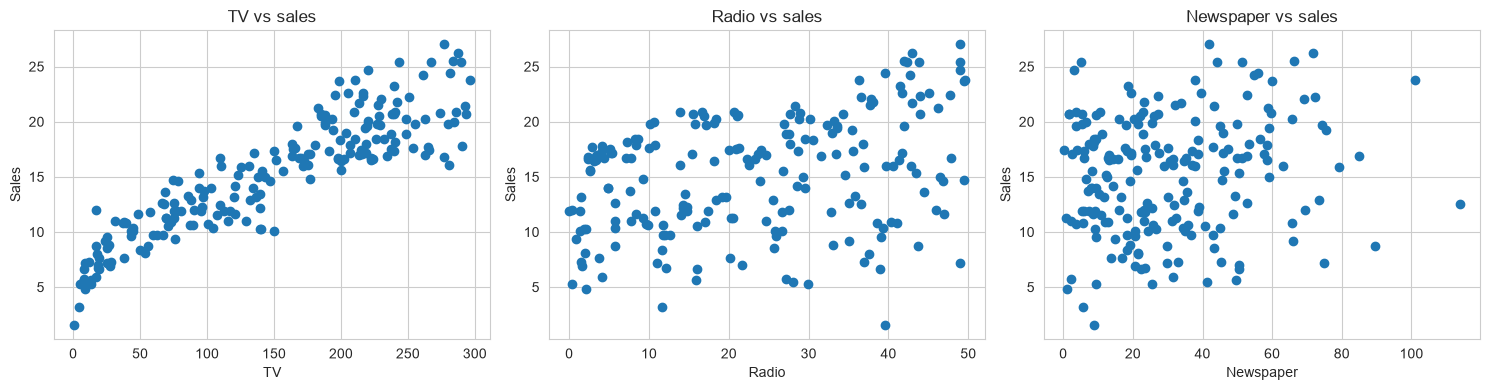

In [ ]:
plt.figure(figsize=(15,4))

for i, col in enumerate(['TV','Radio','Newspaper'], start=1):
    plt.subplot(1,3,i)  # (rows, columns, plot number)
    plt.scatter(df[col],df["Sales"])
    plt.xlabel(col)
    plt.ylabel("Sales")
    plt.title(f'{col} vs sales')

plt.tight_layout()
plt.show()

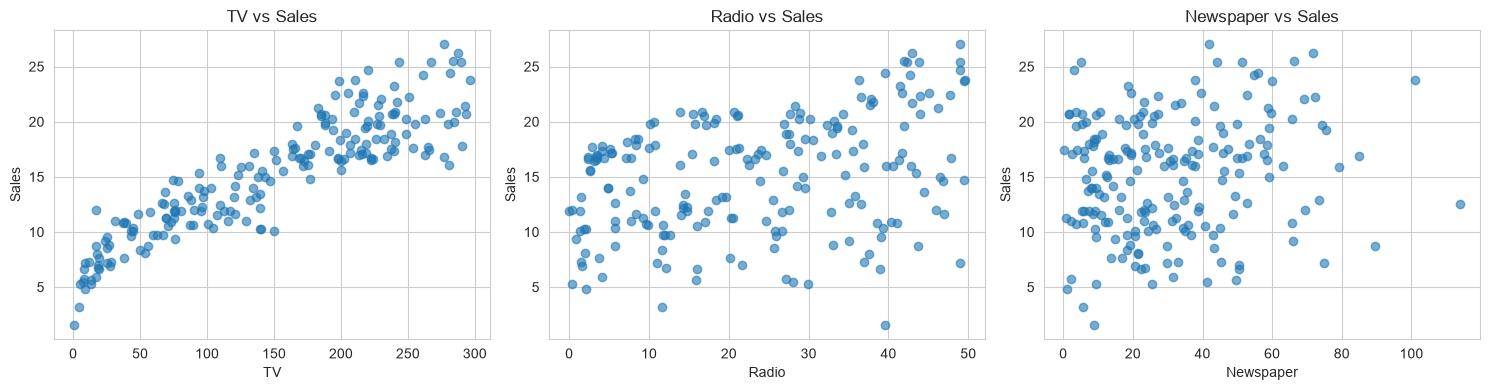

In [116]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    ax.scatter(df[col], df["Sales"], alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("Sales")
    ax.set_title(f"{col} vs Sales")

plt.tight_layout()
plt.show()

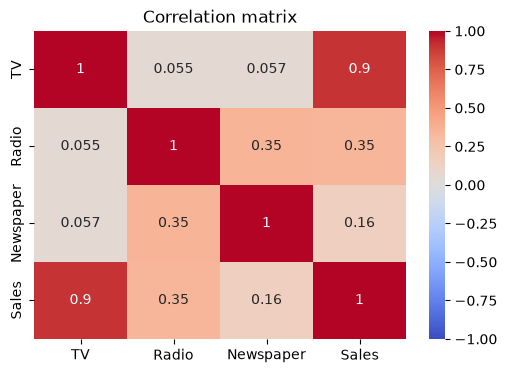

In [97]:
plt.figure(figsize=(6,4))

sns.heatmap(df.corr(),annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()



Simple linear regression: TV spending → Sales

We first use one feature (TV) to predict Sales. The dataset is split into training and test sets so we can evaluate predictions on held-out data.

Model form: Sales = m × TV + b.

In [98]:
x = df[["TV"]]
y = df[["Sales"]]

x_train , x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print('Train size:' ,x_train.shape[0])
print('Train size:', x_test.shape[0])


Train size: 160
Train size: 40


In [99]:
model_simple = LinearRegression()
model_simple.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.06]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['TV']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7.01]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [117]:
m = model_simple.coef_[0]
b= model_simple.intercept_

print(f"Slope(m)   = {m[0]:.4f}")
print(f"Intercept (b)   = {b[0]:.4f}")

print()

print(f"Sales = {m[0]:.4f} x TV + {b[0]:.4f}")


Slope(m)   = 0.0555
Intercept (b)   = 7.0071

Sales = 0.0555 x TV + 7.0071


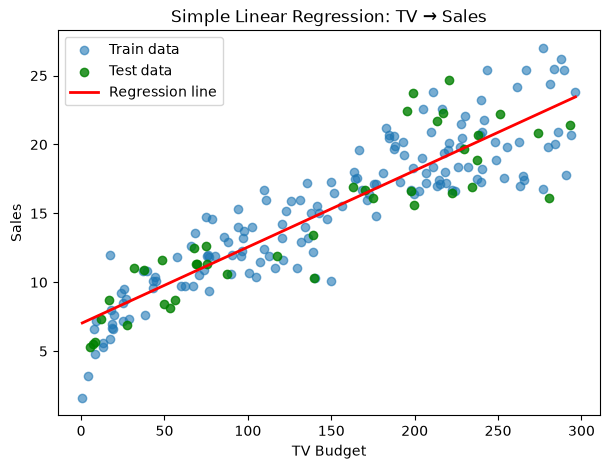

In [101]:
plt.figure(figsize=(7, 5))
plt.scatter(x_train, y_train, alpha=0.6, label="Train data")
plt.scatter(x_test, y_test, color="green", alpha=0.8, label="Test data")

x_line = np.linspace(x["TV"].min(), x["TV"].max(), 100).reshape(-1, 1)
x_line_df = pd.DataFrame(x_line, columns=["TV"])
plt.plot(x_line, model_simple.predict(x_line_df), color="red", linewidth=2, label="Regression line")

plt.xlabel("TV Budget")
plt.ylabel("Sales")
plt.title("Simple Linear Regression: TV → Sales")
plt.legend()
plt.show()

In [ ]:
new_data = pd.DataFrame({"TV": [100]})
print("Predicted Sales for TV=100:", model_simple.predict(new_data)[0].round(2)) 

Predicted Sales for TV=100: [12.56]


In [ ]:
y_pred_simple = model_simple.predict(x_test)

In [104]:
comparison = pd.DataFrame({
    "TV": x_test["TV"].values,
    "Actual": y_test.values.ravel(),
    "Predicted": y_pred_simple.ravel().round(2)
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
).round(2)

comparison.head(10)

,TV,Actual,Predicted,Error
0,163.3,16.9,16.07,0.83
1,195.4,22.4,17.85,4.55
2,292.9,21.4,23.26,-1.86
3,11.7,7.3,7.66,-0.36
4,220.3,24.7,19.23,5.47
5,75.1,12.6,11.17,1.43
6,216.8,22.3,19.04,3.26
7,50.0,8.4,9.78,-1.38
8,222.4,16.5,19.35,-2.85
9,175.1,16.1,16.72,-0.62


Evaluate the simple model
- MAE: average absolute prediction error (lower is better).
- MSE / RMSE: error measures that penalize larger mistakes more strongly (lower is better).
- R²: describes how much variation in the test target is accounted for by the model relative to a baseline. Higher is generally better; R² can be negative on some datasets.

In [105]:
mae = mean_absolute_error(y_test, y_pred_simple)
mse = mean_squared_error(y_test, y_pred_simple)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_simple)

print(f"MAE = {mae:.3f}")
print(f"MSE = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R² = {r2:.3f}")

MAE = 1.950
MSE = 6.101
RMSE = 2.470
R² = 0.803


* Multiple linear regression

In [106]:
features = ["TV", "Radio", "Newspaper"]
X = df[features]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.05,0.1 ,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.714
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [107]:
coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": model_multi.coef_.round(4),
})
print("Intercept:", round(model_multi.intercept_, 4))
coef_df

Intercept: 4.7141


,Feature,Coefficient
0,TV,0.0545
1,Radio,0.1009
2,Newspaper,0.0043


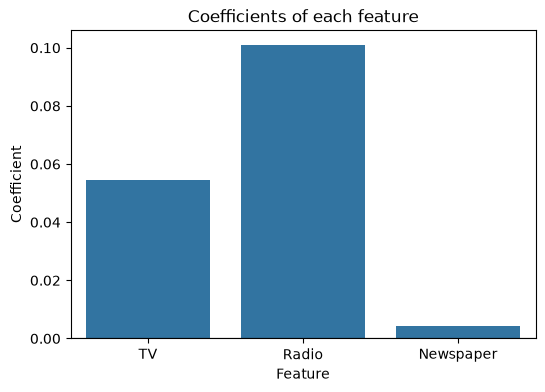

In [108]:
plt.figure(figsize=(6, 4))
sns.barplot(x="Feature", y="Coefficient", data=coef_df)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Coefficients of each feature")
plt.show()

Interpreting coefficients: In a multiple regression model, each coefficient describes the predicted change in Sales for a one-unit increase in that feature, holding the other included features constant. Coefficients describe model associations, not proof of causation. Here, the Newspaper coefficient is small compared with the others.

In [109]:
y_pred_multi = model_multi.predict(X_test)

print(f"MAE  = {mean_absolute_error(y_test, y_pred_multi):.3f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_multi)):.3f}")
print(f"R²   = {r2_score(y_test, y_pred_multi):.3f}")

MAE  = 1.275
RMSE = 1.705
R²   = 0.906


* Compare feature combinations

We train several linear regression models using different sets of advertising features, then compare their test-set R² and MAE under the same train/test split.

In [110]:
experiments = {
    "TV only":                    ["TV"],
    "Radio only":                 ["Radio"],
    "Newspaper only":             ["Newspaper"],
    "TV + Radio":                 ["TV", "Radio"],
    "TV + Radio + Newspaper":     ["TV", "Radio", "Newspaper"],
}

results = []
for name, cols in experiments.items():
    Xtr, Xte, ytr, yte = train_test_split(df[cols], df["Sales"], test_size=0.2, random_state=42)
    mdl = LinearRegression().fit(Xtr, ytr)
    pred = mdl.predict(Xte)
    results.append({
        "Model": name,
        "R²": round(r2_score(yte, pred), 3),
        "MAE": round(mean_absolute_error(yte, pred), 3),
    })

results_df = pd.DataFrame(results)
results_df

,Model,R²,MAE
0,TV only,0.803,1.950
1,Radio only,0.107,4.597
2,Newspaper only,0.005,4.764
3,TV + Radio,0.908,1.267
4,TV + Radio + Newspaper,0.906,1.275


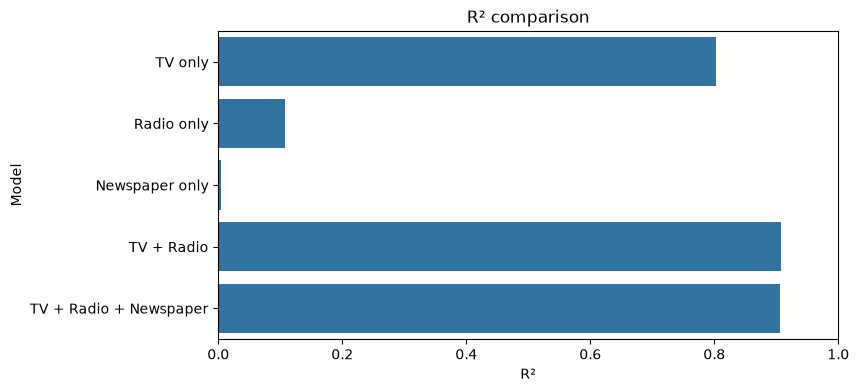

In [111]:
plt.figure(figsize=(8, 4))
sns.barplot(x="R²", y="Model", data=results_df, orient="h")
plt.xlim(0, 1)
plt.title("R² comparison")
plt.show()

Key observations
- Adding Radio to TV substantially improves prediction performance in this exercise.
- Including Newspaper adds little improvement to this particular comparison.
- More features do not automatically guarantee a better model; usefulness depends on the data and evaluation results.


Scope: This is an introductory classroom exercise using one fixed 80/20 split (random_state=42), not a production forecasting system.

In [112]:
new_market = pd.DataFrame({
    "TV": [150],
    "Radio": [30],
    "Newspaper": [20],
})

prediction = model_multi.predict(new_market)[0]
print(f"Predicted Sales: {prediction:.2f}")

Predicted Sales: 16.01


*Summary*

On the held-out test set, the TV-only model achieved R² ≈ 0.662 and MAE ≈ 2.457, while the TV + Radio + Newspaper model achieved R² ≈ 0.906 and MAE ≈ 1.275. These are results from the supplied classroom notebook, using a fixed train/test split.

What I practiced: loading and inspecting data, exploring feature relationships, fitting simple and multiple linear regression models, making predictions, and comparing evaluation metrics.

Next learning steps: understand coefficients and error metrics more deeply, explore cross-validation, and test how results change with different feature combinations.